<h2>Modelling: Future Price Volatility 1

In [4]:
import pandas as pd
import numpy as np

In [5]:
from project_paths import RAW_DATA_PATH
raw_data = pd.read_pickle(RAW_DATA_PATH)
raw_data.head()

Price,Date,Close,High,Low,Open,Volume
0,2014-09-17,457.334015,468.174011,452.421997,465.864014,21056800
1,2014-09-18,424.440002,456.859985,413.104004,456.859985,34483200
2,2014-09-19,394.795990,427.834991,384.532013,424.102997,37919700
3,2014-09-20,408.903992,423.295990,389.882996,394.673004,36863600
4,2014-09-21,398.821014,412.425995,393.181000,408.084991,26580100


<h3>What is the best metric used to express the volatility label?</h3>

This will most likely be realised future volatility defined as:

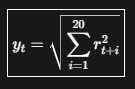

,where:

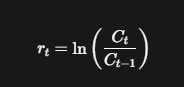

, which is daily log return. C_t is today's close, and C_t-1 is yesterday's close.

We can also add other volatility metrics which can act as features to help predict the label. These are:
- Daily log return (r_t)
- Absolute return (|r_t|)
- Squared return (r_t^2)
- Parkinson volatility (considers high and low prices of a price candle):

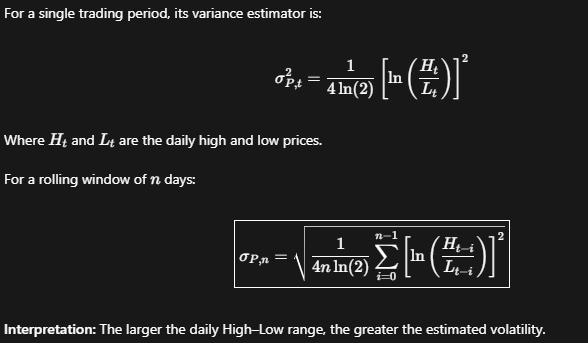

- Garman-Klass volatility (considers high, low, open and close prices of a candle):

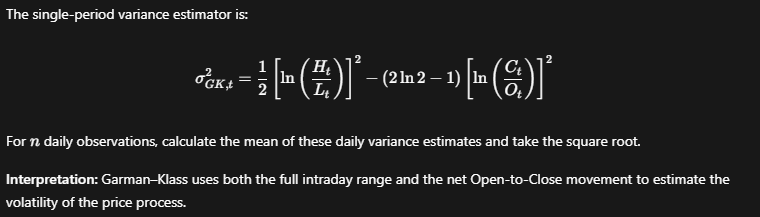 

- Realised historical volatility over 5, 10, 20, and 60 days looking into the past (rv_nd, similar to future volatility except it uses r_t-1 instead of r_t+1).
    - Using a range of time periods allow both short and long term volatility spikes to inform the model about volatility behaviour of the instrument.

In [6]:
H = 20 # Look-ahead period, 20 days in our case, the same as the direcion model.

# Create a copy of raw_data for manipulation:
df = raw_data.copy()

# Affirm that first observation is the oldest one, then drop the date column:
df = df.sort_values("Date", ascending=True).reset_index(drop=True)
df = df.drop(columns=["Date"])

# Daily returns
r = np.log(df["Close"] / df["Close"].shift(1))
r2 = r.pow(2)

# Historical features (past/current observations only)
df["log_return"] = r
df["abs_return"] = r.abs()
df["squared_return"] = r2

for window in [5, 10, 20, 60]:
    df[f"rv_{window}d"] = np.sqrt(
        r2.rolling(window).sum()
    )

# Range-based variance features
hl = np.log(df["High"] / df["Low"])
co = np.log(df["Close"] / df["Open"])

df["parkinson_var"] = hl**2 / (4 * np.log(2))
df["gk_var"] = 0.5 * hl**2 - (2 * np.log(2) - 1) * co**2

df["parkinson_vol_20d"] = np.sqrt(
    df["parkinson_var"].rolling(20).sum()
)

df["gk_vol_20d"] = np.sqrt(
    df["gk_var"].rolling(20).sum().clip(lower=0)
)

# Future 20-day volatility label
df["target_vol_20d"] = np.sqrt(
    r2.rolling(H).sum().shift(-H)
)

df.dropna(inplace=True)
df.head()

Price,Close,High,Low,Open,Volume,log_return,abs_return,squared_return,rv_5d,rv_10d,rv_20d,rv_60d,parkinson_var,gk_var,parkinson_vol_20d,gk_vol_20d,target_vol_20d
60,387.881989,390.799011,374.601990,374.730011,11905600,0.030758,0.030758,0.000946,0.165154,0.174279,0.197199,0.302961,0.000646,0.000436,0.171142,0.159725,0.097072
61,387.407990,410.199005,377.502014,388.348999,41518800,-0.001223,0.001223,0.000001,0.085271,0.173146,0.196772,0.293624,0.002489,0.003448,0.177839,0.169732,0.097068
62,375.197998,392.402008,371.117004,387.785004,32222500,-0.032024,0.032024,0.001026,0.090840,0.175856,0.188953,0.286354,0.001122,0.001135,0.176716,0.171248,0.098374
63,380.554993,386.480988,373.895996,373.895996,18931800,0.014177,0.014177,0.000201,0.072910,0.169142,0.187323,0.284547,0.000395,0.000428,0.175654,0.170274,0.101059
64,357.839996,382.024994,356.781006,380.307007,25233200,-0.061545,0.061545,0.003788,0.077213,0.179711,0.196113,0.290054,0.001686,0.000904,0.179373,0.171870,0.081891


In [7]:
# Reusable function to add volatility features to the OHLCV data.

def add_volatility_features(data: pd.DataFrame, horizon: int = 20, windows: tuple[int, ...] = (5, 10, 20, 60), range_window: int = 20) -> pd.DataFrame:
    """
    Build volatility features and the future realised volatility label from OHLCV data.

    Features use only past/current observations. The label is the realised
    volatility over the next `horizon` days (computed from future returns).

    Args:
        data: DataFrame with "Close", "High", "Low" and "Open" columns.
        horizon: Look-ahead period (days) for the target label.
        windows: Rolling windows (days) for historical realised volatility (rv_{n}d).
        range_window: Rolling window (days) for Parkinson and Garman-Klass volatility.

    Returns:
        New DataFrame (input is not modified) with added feature columns and
        `target_vol_{horizon}d`, with NaN rows removed.

    Example:
        >>> df = add_volatility_features(raw_data)
        >>> df = add_volatility_features(raw_data, horizon=10, windows=(5, 20))
    """
    df = data.copy()

    # Daily returns
    r = np.log(df["Close"] / df["Close"].shift(1))
    r2 = r ** 2

    # Historical features (past/current observations only)
    df["log_return"] = r
    df["abs_return"] = np.abs(r)
    df["squared_return"] = r2

    for w in windows:
        squared_returns = pd.Series(r2, index=df.index)
        df[f"rv_{w}d"] = np.sqrt(squared_returns.rolling(w).sum())

    # Range-based variance features
    hl = np.log(df["High"] / df["Low"])
    co = np.log(df["Close"] / df["Open"])

    df["parkinson_var"] = hl**2 / (4 * np.log(2))
    df["gk_var"] = 0.5 * hl**2 - (2 * np.log(2) - 1) * co**2

    df[f"parkinson_vol_{range_window}d"] = np.sqrt(df["parkinson_var"].rolling(range_window).sum())
    df[f"gk_vol_{range_window}d"] = np.sqrt(df["gk_var"].rolling(range_window).sum().clip(lower=0))

    # Future realised volatility label
    squared_returns = pd.Series(r2, index=df.index)
    df[f"target_vol_{horizon}d"] = np.sqrt(
        squared_returns.rolling(horizon).sum().shift(-horizon)
    )

    return df.dropna()

<h3>Data Preparation for Model Training:</h3>

- Raw data -> data + volatility features.
- Data splitting: Chronological 70/15/15 split.
- Pipeline:
    - Feature scaling: StandardScaler or RobustScaler, fitted on training data only.
    - Lookback (RollingWindowTransformer): 48 daily observations, like the direction model.
- LSTM input: (samples, 60, n_features), with validation + evaluation.

In [8]:
target = "target_vol_20d"

X = df.drop(columns=[target])
y = df[target]

split_idx = int(len(X) * 0.8)
val_idx = int(split_idx * 0.8)

X_train, X_val, X_test = X.iloc[:val_idx], X.iloc[val_idx:split_idx], X.iloc[split_idx:]
y_train, y_val, y_test = y.iloc[:val_idx], y.iloc[val_idx:split_idx], y.iloc[split_idx:]

print(f"Training samples: {len(X_train)} | Validation samples: {len(X_val)} | Test samples: {len(X_test)}")

Training samples: 2764 | Validation samples: 691 | Test samples: 864


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

# Custom lookback window feature transformer (same as the direction pipeline)
class RollingWindowTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, lookback=96):
        self.lookback = lookback

    def fit(self, X, y=None):
        X = np.asarray(X)
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X):
        check_is_fitted(self)

        X = np.asarray(X, dtype=np.float32)

        if X.ndim != 2:
            raise ValueError("X must be 2D")

        if X.shape[1] != self.n_features_in_:
            raise ValueError("Number of features has changed")

        if not 1 <= self.lookback <= len(X):
            raise ValueError("Invalid lookback")

        return np.stack([
            X[i:i + self.lookback]
            for i in range(len(X) - self.lookback + 1)
        ])

In [10]:
# Assemble the processing pipeline:

lookback = 48 # Same as the direction model

process_pipeline = Pipeline([
    ("scaler", RobustScaler()),
    ("rolling", RollingWindowTransformer(lookback=lookback))
])

In [11]:
# Apply the pipeline

X_train_seq = process_pipeline.fit_transform(X_train)
X_val_seq = process_pipeline.transform(X_val)
X_test_seq = process_pipeline.transform(X_test)

print(X_train_seq.shape)
print(X_val_seq.shape)
print(X_test_seq.shape)

(2717, 48, 16)
(644, 48, 16)
(817, 48, 16)


In [12]:
# The rolling transformation reduces the number of samples by lookback - 1. Consequently, the target must be aligned with the end of each sequence:

y_train_seq = np.asarray(y_train)[lookback - 1:]
y_val_seq = np.asarray(y_val)[lookback - 1:]
y_test_seq = np.asarray(y_test)[lookback - 1:]

print(y_train_seq.shape)
print(y_val_seq.shape)
print(y_test_seq.shape)

(2717,)
(644,)
(817,)


In [13]:
# Shape lengths match nicely

In [14]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

In [20]:
# Next, create the LSTM. Simple starting configuration:

model = Sequential([
    Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1, activation="softplus") #If log volatility target, use linear. Here it isn't log.
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.Huber(),
    metrics=["mae"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         6,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,817 (26.63 KB)

 Trainable params: 6,817 (26.63 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=20,
        min_lr=1e-5
    )
]

history = model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=150,
    batch_size=32,
    shuffle=False,
    callbacks=callbacks
)


Epoch 1/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0519 - mae: 0.2705 - val_loss: 0.0072 - val_mae: 0.0989 - learning_rate: 0.0010
Epoch 2/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0063 - mae: 0.0829 - val_loss: 0.0021 - val_mae: 0.0565 - learning_rate: 0.0010
Epoch 3/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0038 - mae: 0.0633 - val_loss: 0.0031 - val_mae: 0.0695 - learning_rate: 0.0010
Epoch 4/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0035 - mae: 0.0615 - val_loss: 0.0027 - val_mae: 0.0657 - learning_rate: 0.0010
Epoch 5/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0033 - mae: 0.0598 - val_loss: 0.0025 - val_mae: 0.0629 - learning_rate: 0.0010
Epoch 6/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0032 - mae: 0.0581 - val_loss: 0.0027 - val_mae: 0.0645 - learning_rate: 0.0010
Epoch 7/150
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0032 - mae: 0.0587 - val_loss: 0.0024 - val_mae: 0.0606 - learning_rate: 0.0010
Epoch 8/150
8

Evaluation:

In [22]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [24]:
def evaluate_volatility(model, X_test, y_test, baseline_vol):
    # Predictions are already on the original volatility scale
    y_true = np.asarray(y_test).ravel()
    y_pred = model.predict(X_test, verbose=0).ravel()
    baseline = np.asarray(baseline_vol).ravel() # Should be 'rv_20d' from the *test* data before pipeline applied to it... 

    def get_metrics(pred):
        actual_var = y_true**2
        pred_var = np.maximum(pred**2, 1e-12)

        return {
            "MAE": mean_absolute_error(y_true, pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
            "R2": r2_score(y_true, pred),
            "QLIKE": np.mean(
                np.log(pred_var) + actual_var / pred_var
            ),
            "Correlation": np.corrcoef(y_true, pred)[0, 1]
        }

    results = pd.DataFrame({
        "LSTM": get_metrics(y_pred),
        "Persistence": get_metrics(baseline)
    }).T

    results["MAE Skill"] = (
        1 - results["MAE"] / results.loc["Persistence", "MAE"]
    )

    return results, y_true, y_pred


In [28]:
baseline_vol = X_test["rv_20d"].to_numpy()[lookback - 1:]

In [ ]:
evaluation, y_true, y_pred = evaluate_volatility(model, X_test_seq, y_test_seq, baseline_vol)

,MAE,RMSE,R2,QLIKE,Correlation,MAE Skill
LSTM,0.078462,0.084801,-4.663177,-3.095351,-0.180359,-1.270194
Persistence,0.034562,0.046098,-0.673478,-3.211866,0.167571,0.000000
